# CSE 242 Assignment 1 — Part 3, Q2-Q4 and Figures
### Mathis Aubert - Maths-A

In [2]:
# Libraries
import numpy as np
import matplotlib.pyplot as plt

## P3 Q2: Describe the Gaussian generator and observed correlation.
Generate a synthetic 2-dimensional dataset composed of two correlated Gaussian features. Use NumPy for data generation.

In [3]:
def generate_data(n_samples=500, seed=0, mean=np.array([2.0, -1.0]), covariance=np.array([[3.0, 1.2], [1.2, 1.0]])):
    """Return reproducible Gaussian samples (n_samples,2) using NumPy and seed.

    Defaults: mean=[2,-1], covariance=[[3,1.2],[1.2,1]]. Custom mean has shape
    (2,), covariance (2,2) is positive definite. Do not mutate input arrays.
    """
    # The default mean and covariance are defined in the function signature.
    # The np.random.default_rng(seed) creates a reproducible random number generator.
    rng = np.random.default_rng(seed)
    # The rng.multivariate_normal function draws samples from a multivariate normal distribution with the specified mean and covariance.
    X = rng.multivariate_normal(mean=mean, cov=covariance, size=n_samples)
    return X

Visualize this dataset with scatter plots and discuss the correlation structure observed.

Correlation: 0.6992223066425662


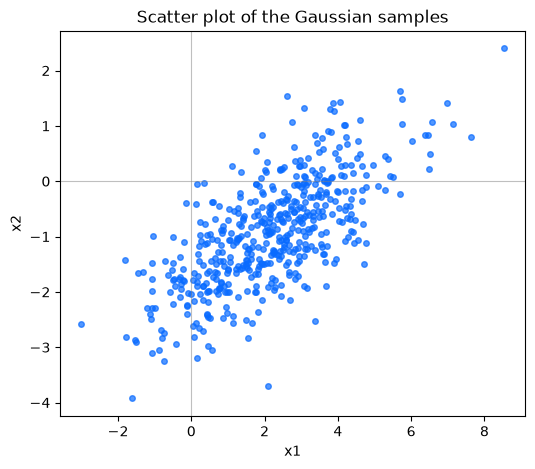

In [4]:
# Generate the data and inspect its correlation structure
X = generate_data()
# Calculate the sample correlation coefficient between the two variables of the generated data.
correlation = np.corrcoef(X[:, 0], X[:, 1])[0, 1]
print(f"Correlation: {correlation}")

# Create a scatter plot of the generated Gaussian samples.
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(X[:, 0], X[:, 1], s=16, alpha=0.7, color="#096BFF")
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_title('Scatter plot of the Gaussian samples')
ax.axhline(0, color='gray', lw=0.8, alpha=0.5)
ax.axvline(0, color='gray', lw=0.8, alpha=0.5)

The data shows a clear positive linear correlation between the two variables.

## P3 Q3: Centering, covariance, eigendecomposition, and the plot

Implement PCA from scratch using NumPy. Follow these steps:
- Center your dataset (mean subtraction).
- Compute the covariance matrix.
- Find eigenvalues and eigenvectors of the covariance matrix.
- Select the principal components corresponding to the highest eigenvalues.

In [5]:
def pca(X):
    """Fit NumPy PCA without mutating finite X of shape (n,2), n>=2.

    Return dict: mean (2,), centered (n,2), covariance (2,2), eigenvalues (2,),
    components (2,2), scores (n,2). Use covariance divisor n-1, descending
    eigenvalues, orthonormal eigenvectors as columns, scores=centered@components.
    Signs/tied-eigenspace bases are free. Include rank-deficient and tied cases.
    NumPy eigh/SVD are allowed; fitted library PCA is not.
    """
    # Calculate the mean of the data along each feature.
    mean = X.mean(axis=0)
    # Center the data by subtracting the mean from each observation.
    centered = X - mean
    # Calculate the covariance matrix of the centered data. 
    # The covariance matrix is computed as the dot product of the transposed centered data and the centered data, divided by (n-1), 
    # where n is the number of samples.
    covariance = (centered.T @ centered) / (X.shape[0] - 1)

    # Compute the eigenvalues and eigenvectors of the covariance matrix using NumPy's linear algebra module.
    eigenvalues, eigenvectors = np.linalg.eigh(covariance)
    # Sort the eigenvalues in descending order and reorder the eigenvectors accordingly.
    order = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[order]
    # Calculate the principal components by reordering the eigenvectors according to the sorted eigenvalues.
    components = eigenvectors[:, order]
    # Calculate the scores by projecting the centered data onto the principal components.
    scores = centered @ components

    return {
        'mean': mean,
        'centered': centered,
        'covariance': covariance,
        'eigenvalues': eigenvalues,
        'components': components,
        'scores': scores,
    }

Provide visualizations of your original data along with identified principal component directions.

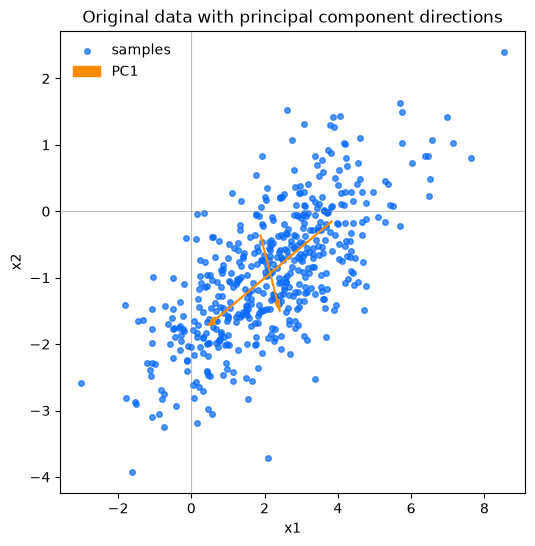

In [6]:
# Run PCA on the generated data and store the results in a dictionary.
result = pca(X)

# Plot the data and the principal component directions
mean = result['mean']
components = result['components']
eigenvalues = result['eigenvalues']

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(X[:, 0], X[:, 1], s=16, alpha=0.7, color='#096BFF', label='samples')

for i in range(len(eigenvalues)):
    direction = components[:, i] * np.sqrt(max(eigenvalues[i], 0.0))
    ax.arrow(
        mean[0] - direction[0], mean[1] - direction[1],
        2 * direction[0], 2 * direction[1],
        color='darkorange', width=0.015, head_width=0.12, length_includes_head=True,
        label=f'PC{i + 1}' if i == 0 else None
    )

ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_title('Original data with principal component directions')
ax.axhline(0, color='gray', lw=0.8, alpha=0.5)
ax.axvline(0, color='gray', lw=0.8, alpha=0.5)
ax.legend(loc='best', frameon=False)

## P3 Q4: Explained variance fractions and the reduction tradeoff

Compute the proportion of total variance explained by each principal component. Discuss the results and explain the significance of dimensionality reduction. Provide insights into the trade-off between explained variance and dimensionality reduction.

In [7]:
def explained_variance(eigenvalues):
    """Return same-shape fractions for nonnegative eigenvalues with positive sum."""
    # Calculate the explained variance fractions by dividing each eigenvalue by the sum of all eigenvalues.
    return eigenvalues / eigenvalues.sum()

fractions = explained_variance(result['eigenvalues'])
fractions

array([0.89385326, 0.10614674])


PCA is useful because it allows us to keep the most informative directions and discard the rest.

For this example, keeping only PC1 reduces the data from 2 dimensions to 1 but it still retains about 89.4% of the total variance.
This is a strong dimensionality reduction with relatively little information loss.

Trade-off between explained variance and dimensionality reduction:

Fewer dimensions → simpler, faster, lower-memory representation,
But too much reduction → lose information and accuracy